# 03 · Clasificación: optimización, métricas, umbrales y calibración

**Objetivo:** entrenar regresión logística desde cero (y ver por qué el solver importa),
elegir métricas adecuadas con clases desbalanceadas, fijar un umbral según costos y
comprobar si las probabilidades significan lo que dicen.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from applied_ml import LogisticRegression
from applied_ml.metrics import (
    average_precision,
    calibration_bins,
    expected_calibration_error,
    precision_recall_curve,
    roc_auc,
    roc_curve,
)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.datasets import load_breast_cancer, make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler

## 1. El solver importa: GD vs. Newton

La pérdida logística es convexa, pero su condicionamiento depende de las escalas de las features.
GD necesita ~$\sqrt{\kappa}$ iteraciones (con momentum); Newton converge cuadráticamente.

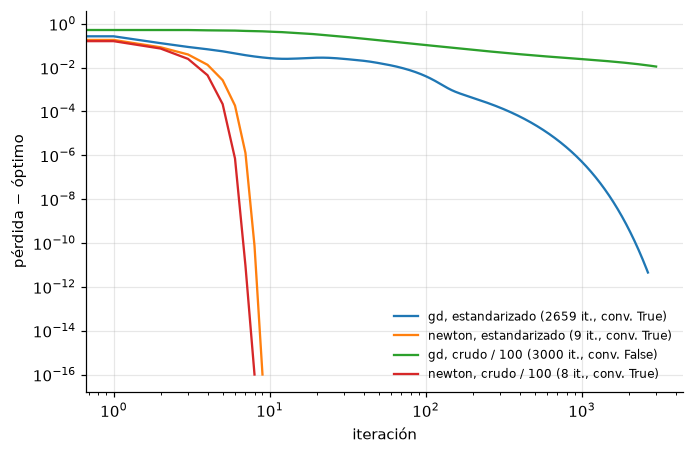

In [2]:
X, y = load_breast_cancer(return_X_y=True)
fig, ax = plt.subplots()
for name, Xs in [("estandarizado", StandardScaler().fit_transform(X)), ("crudo / 100", X / 100)]:
    # óptimo de referencia: Newton con tolerancia estricta sobre los mismos datos
    optimum = (
        LogisticRegression(alpha=1e-3, solver="newton", tol=1e-12).fit(Xs, y).loss_history_[-1]
    )
    for solver in ["gd", "newton"]:
        iters = 3000 if solver == "gd" else 50
        m = LogisticRegression(alpha=1e-3, solver=solver, max_iter=iters).fit(Xs, y)
        gap = np.maximum(np.array(m.loss_history_) - optimum, 1e-16)
        ax.semilogy(gap, label=f"{solver}, {name} ({m.n_iter_} it., conv. {m.converged_})")
ax.set_xscale("log")
ax.set_xlabel("iteración")
ax.set_ylabel("pérdida − óptimo")
ax.legend(fontsize=8);

## 2. Clases desbalanceadas: la paradoja de la accuracy

5 % de positivos. Un modelo que dice siempre “negativo” tiene 95 % de accuracy y no sirve.

In [3]:
Xi, yi = make_classification(
    20_000,
    n_features=10,
    n_informative=4,
    weights=[0.95],
    flip_y=0.01,
    class_sep=0.8,
    random_state=0,
)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.5, stratify=yi, random_state=0)
scores = {
    "logística": LogisticRegression(alpha=1e-3).fit(Xi_tr, yi_tr).predict_proba(Xi_te)[:, 1],
    "random forest": RandomForestClassifier(200, min_samples_leaf=3, random_state=0, n_jobs=-1)
    .fit(Xi_tr, yi_tr)
    .predict_proba(Xi_te)[:, 1],
}
print(f"prevalencia en test: {yi_te.mean():.3f} → accuracy de 'siempre 0': {1 - yi_te.mean():.3f}")
for name, s in scores.items():
    acc = np.mean((s >= 0.5) == yi_te)
    print(
        f"{name:<14} accuracy@0.5 = {acc:.3f}   AUC = {roc_auc(yi_te, s):.3f}"
        f"   AP = {average_precision(yi_te, s):.3f}"
    )

prevalencia en test: 0.054 → accuracy de 'siempre 0': 0.946
logística      accuracy@0.5 = 0.946   AUC = 0.722   AP = 0.324
random forest  accuracy@0.5 = 0.958   AUC = 0.911   AP = 0.584


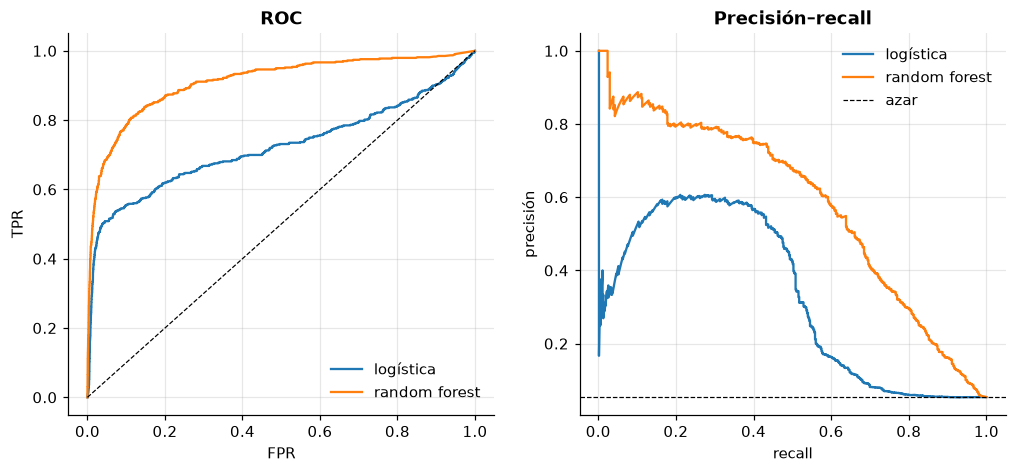

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(yi_te, s)
    axes[0].plot(fpr, tpr, label=name)
    p, r, _ = precision_recall_curve(yi_te, s)
    axes[1].plot(r, p, label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1].axhline(yi_te.mean(), color="k", ls="--", lw=0.8, label="azar")
axes[0].set(xlabel="FPR", ylabel="TPR", title="ROC")
axes[1].set(xlabel="recall", ylabel="precisión", title="Precisión–recall")
for ax in axes:
    ax.legend()

AUC no depende de la prevalencia (compara un positivo con un negativo); la curva PR sí,
y por eso muestra mucho mejor el costo de los falsos positivos cuando los positivos son raros.

## 3. Elegir el umbral según costos

Supongamos que un falso negativo cuesta 10 veces un falso positivo. El umbral óptimo ya no es 0.5.
(En la práctica se elige con datos de validación, nunca con el test.)

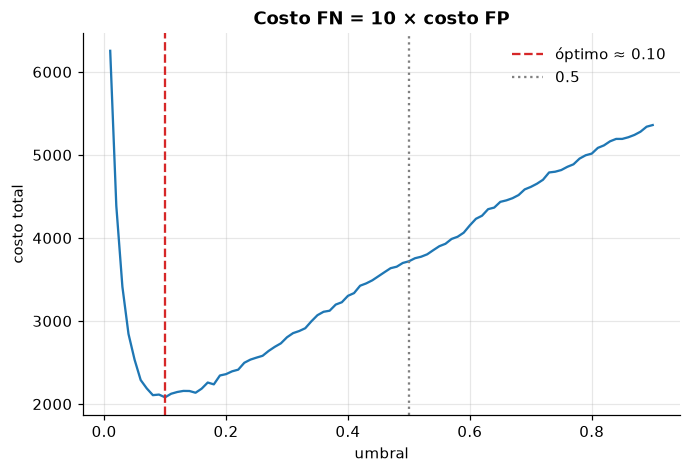

In [5]:
s = scores["random forest"]
thresholds = np.linspace(0.01, 0.9, 90)
cost_fp, cost_fn = 1.0, 10.0
cost = [
    cost_fp * np.sum((s >= t) & (yi_te == 0)) + cost_fn * np.sum((s < t) & (yi_te == 1))
    for t in thresholds
]
best = thresholds[int(np.argmin(cost))]
fig, ax = plt.subplots()
ax.plot(thresholds, cost)
ax.axvline(best, color="C3", ls="--", label=f"óptimo ≈ {best:.2f}")
ax.axvline(0.5, color="gray", ls=":", label="0.5")
ax.set(xlabel="umbral", ylabel="costo total", title="Costo FN = 10 × costo FP")
ax.legend();

Si las probabilidades están calibradas, el umbral de mínimo costo esperado es
$t^* = c_{FP}/(c_{FP} + c_{FN})$, aquí $1/11 \approx 0.09$. Que el óptimo empírico se acerque a ese
valor depende de la calibración, que es la siguiente sección.

## 4. Calibración

Un modelo calibrado que dice “70 %” acierta el 70 % de esas veces. Naive Bayes suele ser
sobreconfiado (asume independencia); random forest, subconfiado (promediar aleja de 0 y 1).

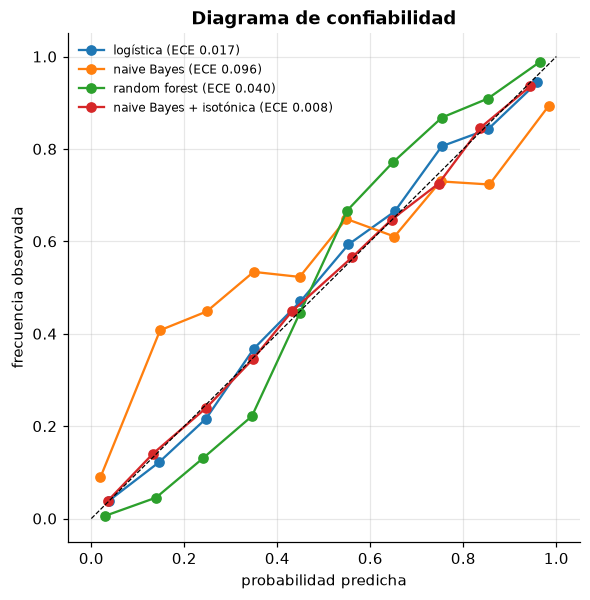

In [6]:
Xk, yk = make_classification(30_000, n_features=20, n_informative=6, n_redundant=6, random_state=3)
Xk_tr, Xk_cal, Xk_te = Xk[:15_000], Xk[15_000:22_000], Xk[22_000:]
yk_tr, yk_cal, yk_te = yk[:15_000], yk[15_000:22_000], yk[22_000:]
models = {
    "logística": LogisticRegression(alpha=1e-4).fit(Xk_tr, yk_tr),
    "naive Bayes": GaussianNB().fit(Xk_tr, yk_tr),
    "random forest": RandomForestClassifier(200, random_state=0, n_jobs=-1).fit(Xk_tr, yk_tr),
}
models["naive Bayes + isotónica"] = CalibratedClassifierCV(
    GaussianNB(), method="isotonic", cv=5
).fit(np.r_[Xk_tr, Xk_cal], np.r_[yk_tr, yk_cal])
fig, ax = plt.subplots(figsize=(6, 6))
for name, m in models.items():
    p = m.predict_proba(Xk_te)[:, 1]
    mp, fr, _ = calibration_bins(yk_te, p, 10)
    ax.plot(mp, fr, "o-", label=f"{name} (ECE {expected_calibration_error(yk_te, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set(
    xlabel="probabilidad predicha", ylabel="frecuencia observada", title="Diagrama de confiabilidad"
)
ax.legend(fontsize=8);

## Para llevar

- Elegir el solver según el condicionamiento y la dimensión: Newton para d moderado, primer orden para d enorme.
- Con desbalance, reportar AUC **y** AP; la accuracy sola engaña.
- El umbral es una decisión de negocio (costos), separada del entrenamiento; elegirlo sin tocar el test.
- AUC alto no implica probabilidades confiables: medir calibración y corregir (isotónica, Platt) si hace falta.